---
title: "Chapter 4: Linear Functions"
subtitle: Notes drawn from OpenStax *Algebra and Trigonometry 2e* (§4.1–4.3) and *Precalculus 2e*
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
    "legend.frameon": True, "legend.facecolor": "#fcfcfb", "legend.edgecolor": "none", "legend.framealpha": 0.92, "figure.dpi": 110,
})

def setup(ax, xlim, ylim, title=None, ticks=1):
    """Axes through the origin, light grid, square units."""
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    for s in ("left", "bottom"):
        ax.spines[s].set_position("zero"); ax.spines[s].set_color(INK2)
    for s in ("right", "top"):
        ax.spines[s].set_visible(False)
    ax.set_xticks(np.arange(np.ceil(xlim[0]), xlim[1] + 0.01, ticks))
    ax.set_yticks(np.arange(np.ceil(ylim[0]), ylim[1] + 0.01, ticks))
    ax.tick_params(labelsize=8)
    ax.grid(color="#e6e5e0", linewidth=0.6); ax.set_axisbelow(True)
    ax.set_aspect("equal")
    if title: ax.set_title(title)

def dot(ax, x, y, filled=True, color=BLUE):
    ax.plot(x, y, "o", ms=7, color=color,
            mfc=color if filled else "#fcfcfb", mew=2, zorder=5)

In [2]:
def data_axes(ax, title=None, xlabel=None, ylabel=None):
    """Plain axes for data plots (no forced square units)."""
    for s in ("right", "top"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color(INK2)
    ax.grid(color="#e6e5e0", linewidth=0.6); ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)
    if title: ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel, fontsize=9, color=INK2)
    if ylabel: ax.set_ylabel(ylabel, fontsize=9, color=INK2)

(sec-4-1)=
## 4.1 Linear Functions

### Slope and the forms of a line

A **linear function** has a constant rate of change. Its graph is a straight line.

$$
m = \frac{\Delta y}{\Delta x} = \frac{y_2 - y_1}{x_2 - x_1}, \qquad x_1 \ne x_2
$$

| Form | Equation | Best when you know |
|---|---|---|
| Slope-intercept | $f(x) = mx + b$ | the slope $m$ and the $y$-intercept $(0, b)$ |
| Point-slope | $y - y_1 = m(x - x_1)$ | the slope and any one point $(x_1, y_1)$ |
| Standard | $Ax + By = C$ | (common in given equations; solve for $y$ to read $m$ and $b$) |
| Horizontal line | $y = b$ | slope $0$; a constant function |
| Vertical line | $x = a$ | slope undefined; **not a function** |

- $m > 0$: increasing. $m < 0$: decreasing. $m = 0$: constant.
- Slope is a **rate of change** in output units per input unit. The $y$-intercept $b$ is the **initial value**, the output when the input is $0$.
- A table is linear exactly when $\dfrac{\Delta y}{\Delta x}$ is the same between every pair of rows. With equally spaced inputs, that means equal differences in the outputs.

**Worked example (two points).** The line through $(-2, 5)$ and $(4, -1)$:

$$
\begin{aligned}
m &= \frac{-1 - 5}{4 - (-2)} = \frac{-6}{6} = -1 \\
y - 5 &= -1\big(x - (-2)\big) \implies y = -x + 3
\end{aligned}
$$

Check with the other point: $-(4) + 3 = -1$. ✓

### Intercepts

- $y$-intercept: set $x = 0$. In $f(x) = mx + b$ it is just $b$.
- $x$-intercept (zero): set $f(x) = 0$ and solve. For $f(x) = -\tfrac{2}{3}x + 4$: $0 = -\tfrac{2}{3}x + 4 \implies x = 6$.
- From standard form, $3x + 4y = 12$: solve for $y$ to get $y = -\tfrac{3}{4}x + 3$, or set each variable to $0$ for the intercepts $(4, 0)$ and $(0, 3)$.

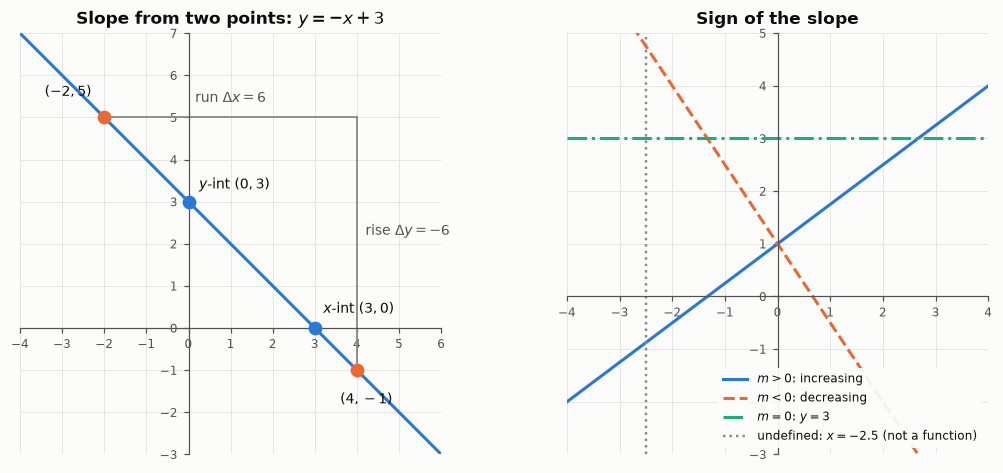

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
ax = axes[0]; setup(ax, (-4, 6), (-3, 7), r"Slope from two points: $y = -x + 3$")
x = np.linspace(-4, 6, 50); ax.plot(x, -x + 3, color=BLUE)
dot(ax, -2, 5, color=ORANGE); dot(ax, 4, -1, color=ORANGE)
ax.plot([-2, 4], [5, 5], color=GRAY, lw=1.2); ax.plot([4, 4], [5, -1], color=GRAY, lw=1.2)
ax.text(1, 5.35, r"run $\Delta x = 6$", ha="center", color=INK2, fontsize=9)
ax.text(4.2, 2.2, r"rise $\Delta y = -6$", color=INK2, fontsize=9)
ax.text(-2.3, 5.5, "$(-2, 5)$", ha="right", fontsize=9); ax.text(3.6, -1.8, "$(4, -1)$", fontsize=9)
dot(ax, 0, 3); dot(ax, 3, 0)
ax.text(0.25, 3.3, "$y$-int $(0, 3)$", fontsize=9); ax.text(3.2, 0.35, "$x$-int $(3, 0)$", fontsize=9)

ax = axes[1]; setup(ax, (-4, 4), (-3, 5), "Sign of the slope")
x = np.linspace(-4, 4, 50)
ax.plot(x, 0.75*x + 1, color=BLUE, label=r"$m > 0$: increasing")
ax.plot(x, -1.5*x + 1, color=ORANGE, ls="--", label=r"$m < 0$: decreasing")
ax.plot(x, np.full_like(x, 3), color=AQUA, ls="-.", label=r"$m = 0$: $y = 3$")
ax.axvline(-2.5, color=GRAY, lw=1.6, ls=":", label=r"undefined: $x = -2.5$ (not a function)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### Graphing and transformations

- **From slope and intercept:** plot $(0, b)$, then move "rise over run" to a second point. A slope of $-\tfrac{2}{3}$ means down 2, right 3.
- **As a transformation of $y = x$:** $f(x) = mx + b$ is the identity function stretched or compressed vertically by $\lvert m \rvert$ (reflected if $m < 0$), then shifted vertically by $b$. This is §3.5 applied to a line.

### Parallel and perpendicular lines

| Relationship | Slopes | Example with $y = 2x - 3$ |
|---|---|---|
| Parallel | $m_1 = m_2$ (different intercepts) | $y = 2x + 5$ |
| Perpendicular | $m_1 m_2 = -1$, i.e. $m_2 = -\dfrac{1}{m_1}$ | $y = -\tfrac{1}{2}x + 1$ |

A horizontal line and a vertical line are perpendicular even though the product rule doesn't apply (vertical slope is undefined).

**Worked example.** Lines through $(1, 4)$ parallel and perpendicular to $y = 2x - 3$:

$$
\begin{aligned}
\text{parallel, } m = 2: &\quad y - 4 = 2(x - 1) \implies y = 2x + 2 \\
\text{perpendicular, } m = -\tfrac{1}{2}: &\quad y - 4 = -\tfrac{1}{2}(x - 1) \implies y = -\tfrac{1}{2}x + \tfrac{9}{2}
\end{aligned}
$$

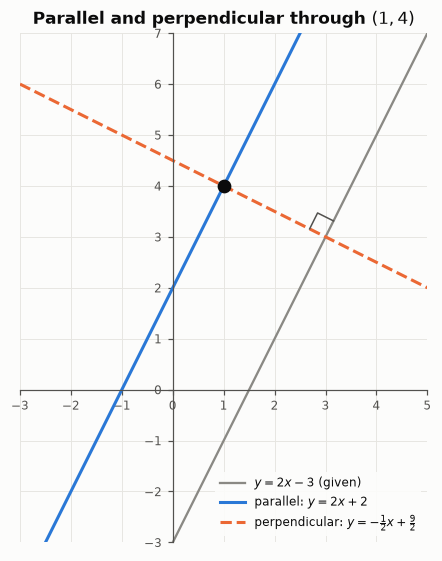

In [4]:
fig, ax = plt.subplots(figsize=(5.4, 5.2))
setup(ax, (-3, 5), (-3, 7), "Parallel and perpendicular through $(1, 4)$")
x = np.linspace(-3, 5, 50)
ax.plot(x, 2*x - 3, color=GRAY, lw=1.5, label="$y = 2x - 3$ (given)")
ax.plot(x, 2*x + 2, color=BLUE, label="parallel: $y = 2x + 2$")
ax.plot(x, -0.5*x + 4.5, color=ORANGE, ls="--", label=r"perpendicular: $y = -\frac{1}{2}x + \frac{9}{2}$")
dot(ax, 1, 4, color=INK)
# right-angle marker where the perpendicular meets the given line: 2x - 3 = -x/2 + 9/2 -> x = 3
px, py = 3, 3; u = np.array([1, 2])/np.sqrt(5); v = np.array([-2, 1])/np.sqrt(5); s = 0.35
ax.plot([px + s*u[0], px + s*u[0] + s*v[0], px + s*v[0]], [py + s*u[1], py + s*u[1] + s*v[1], py + s*v[1]], color=INK2, lw=1)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Mixing the order of the points: $\dfrac{y_2 - y_1}{x_1 - x_2}$ flips the sign. Same point first on top and bottom.
- Putting $x$ on top. Slope is rise over run, $\Delta y / \Delta x$.
- Using the opposite slope for a perpendicular line instead of the **negative reciprocal**: perpendicular to $m = 2$ is $-\tfrac{1}{2}$, not $-2$.
- Reading the slope from standard form without solving for $y$. In $3x + 4y = 12$ the slope is $-\tfrac{3}{4}$, not $3$.
- Saying a horizontal line has "no slope." It has slope $0$. A vertical line's slope is *undefined*.
:::

:::{important} The book underplays this
The book mostly finds equations by plugging a point into $y = mx + b$ and solving for $b$. **Point-slope form** does the same thing in one step and is the form you'll use constantly in calculus. The tangent-line approximation in Stewart, $L(x) = f(a) + f'(a)(x - a)$, is point-slope form with the derivative as the slope.
:::

:::{tip} Where this shows up
In a regression $E[Y \mid x] = \beta_0 + \beta_1 x$, $\beta_1$ is a slope (change in mean response per one-unit change in $x$) and $\beta_0$ is the initial value (mean response at $x = 0$, which is often meaningless unless $x$ is centered). Perpendicular lines generalize to orthogonal vectors (dot product $0$) in Searle.
:::

(sec-4-2)=
## 4.2 Modeling with Linear Functions

### Building a linear model

1. **Define the variables** with units, including what "$t = 0$" means (e.g., $t$ = years since 2018).
2. **Find the rate of change** $m$ (given directly, or from two data points).
3. **Find the initial value** $b$ (given, or solve using a point).
4. **Write the model**, then use it: **evaluate** for a prediction, or **solve** for the input that produces a target output.
5. **State a reasonable domain** and check whether the answer makes sense.

**Worked example.** An elk herd was counted at 420 in 2018 and 345 in 2023. Assume linear change, with $t$ = years since 2018.

$$
\begin{aligned}
m &= \frac{345 - 420}{5 - 0} = -15 \text{ elk per year}, \qquad b = 420 \\
E(t) &= 420 - 15t \\
E(10) &= 420 - 150 = 270 \quad \text{(predicted count in 2028)} \\
E(t) = 0 &\implies t = 28 \quad \text{(the model hits zero in 2046)}
\end{aligned}
$$

A reasonable domain is something like $0 \le t \le 28$, since a negative count is meaningless. Predicting out to 2046 is extrapolating far past the data, so treat it with suspicion (see §4.3).

### Comparing two linear models

To compare two linear models, **set them equal** to find where they cross, then check which is smaller (or larger) on each side.

**Worked example.** Rental plan A costs $\$40$ plus $\$0.25$ per mile; plan B costs $\$10$ plus $\$0.40$ per mile.

$$
\begin{aligned}
A(x) &= 40 + 0.25x, \qquad B(x) = 10 + 0.40x \\
40 + 0.25x &= 10 + 0.40x \implies 30 = 0.15x \implies x = 200
\end{aligned}
$$

At 200 miles both cost $\$90$. For $x < 200$, B is cheaper (smaller fee); for $x > 200$, A is cheaper (smaller per-mile rate).

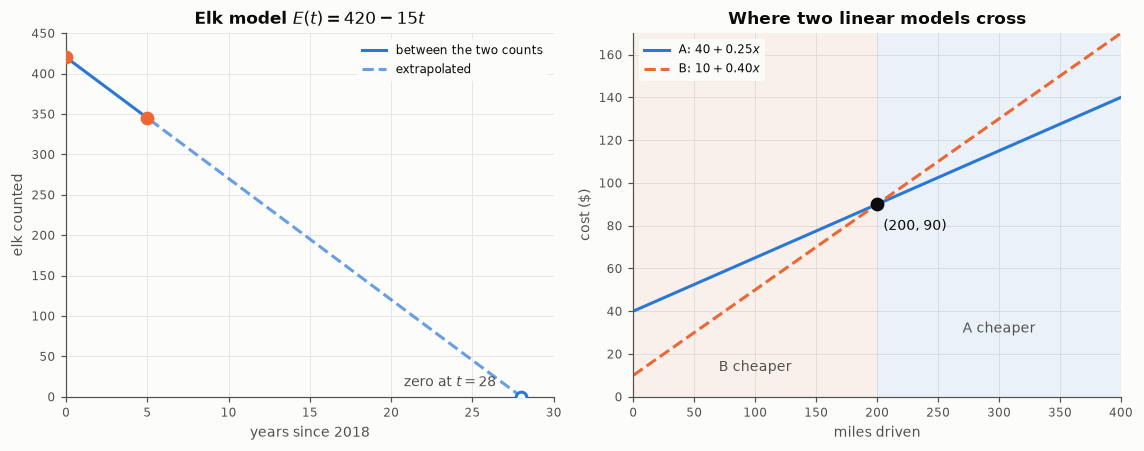

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax = axes[0]; data_axes(ax, "Elk model $E(t) = 420 - 15t$", "years since 2018", "elk counted")
t = np.linspace(0, 30, 100)
ax.plot(t[t <= 5], 420 - 15*t[t <= 5], color=BLUE, label="between the two counts")
ax.plot(t[t >= 5], 420 - 15*t[t >= 5], color=BLUE, ls="--", alpha=0.7, label="extrapolated")
dot(ax, 0, 420, color=ORANGE); dot(ax, 5, 345, color=ORANGE)
dot(ax, 28, 0, filled=False)
ax.text(26.5, 12, "zero at $t = 28$", ha="right", fontsize=9, color=INK2)
ax.set_xlim(0, 30); ax.set_ylim(0, 450); ax.legend(loc="upper right", fontsize=8)

ax = axes[1]; data_axes(ax, "Where two linear models cross", "miles driven", "cost (\\$)")
x = np.linspace(0, 400, 100)
ax.axvspan(0, 200, color=ORANGE, alpha=0.08, lw=0); ax.axvspan(200, 400, color=BLUE, alpha=0.08, lw=0)
ax.plot(x, 40 + 0.25*x, color=BLUE, label="A: $40 + 0.25x$")
ax.plot(x, 10 + 0.40*x, color=ORANGE, ls="--", label="B: $10 + 0.40x$")
dot(ax, 200, 90, color=INK)
ax.text(205, 78, "(200, 90)", fontsize=9)
ax.text(100, 12, "B cheaper", ha="center", color=INK2, fontsize=9)
ax.text(300, 30, "A cheaper", ha="center", color=INK2, fontsize=9)
ax.set_xlim(0, 400); ax.set_ylim(0, 170); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### Models from diagrams

For geometry problems (two people walking at right angles, distance between towns on a map), draw the picture, label distances as linear functions of time, and connect them with the Pythagorean theorem or area formulas. The linear pieces are the legs; the relationship you want may not itself be linear.

:::{admonition} Common mistakes
:class: warning
- Not defining what $t = 0$ is. "The population in 2025" is $P(7)$ if $t$ counts years since 2018, not $P(2025)$.
- Using a decrease as a positive slope. Losing 15 per year means $m = -15$.
- Answering with a bare number. State units and what it means ("about 270 elk in 2028").
- Treating the model's domain as all real numbers. Real quantities usually need $t \ge 0$ and a nonnegative output.
:::

:::{tip} Where this shows up
Most first-pass ecological models are linear in something: temperature declining with elevation at a roughly constant lapse rate, cost of a field season per survey site. Setting two lines equal is solving a $2 \times 2$ linear system, the smallest case of $A\mathbf{x} = \mathbf{b}$, which Searle generalizes to any size.
:::

(sec-4-3)=
## 4.3 Fitting Linear Models to Data

### Scatter plots and the regression line

- A **scatter plot** shows paired data $(x_i, y_i)$. First look at it: is the pattern roughly linear, curved, or absent?
- The **least squares regression line** $\hat{y} = b_0 + b_1 x$ is the line that minimizes the sum of squared **vertical** distances (residuals) $\sum (y_i - \hat{y}_i)^2$. There is exactly one such line.
- **Interpolation** predicts within the range of the observed $x$ values. **Extrapolation** predicts outside it and is much riskier, because nothing in the data says the pattern continues.

The book only fits lines with a calculator. The formulas are short:

$$
b_1 = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2},
\qquad
b_0 = \bar{y} - b_1 \bar{x}
$$

The second formula says the line always passes through $(\bar{x}, \bar{y})$.

**Worked example.** Data: $x = 1, 2, 3, 4, 5$ and $y = 2, 4, 5, 4, 5$. Then $\bar{x} = 3$, $\bar{y} = 4$.

| $x_i$ | $y_i$ | $x_i - \bar{x}$ | $y_i - \bar{y}$ | product | $(x_i - \bar{x})^2$ |
|---|---|---|---|---|---|
| 1 | 2 | $-2$ | $-2$ | $4$ | $4$ |
| 2 | 4 | $-1$ | $0$ | $0$ | $1$ |
| 3 | 5 | $0$ | $1$ | $0$ | $0$ |
| 4 | 4 | $1$ | $0$ | $0$ | $1$ |
| 5 | 5 | $2$ | $1$ | $2$ | $4$ |
| | | | **sum** | $6$ | $10$ |

$$
b_1 = \frac{6}{10} = 0.6, \qquad b_0 = 4 - 0.6(3) = 2.2, \qquad \hat{y} = 2.2 + 0.6x
$$

b0 = 2.20, b1 = 0.60, r = 0.775


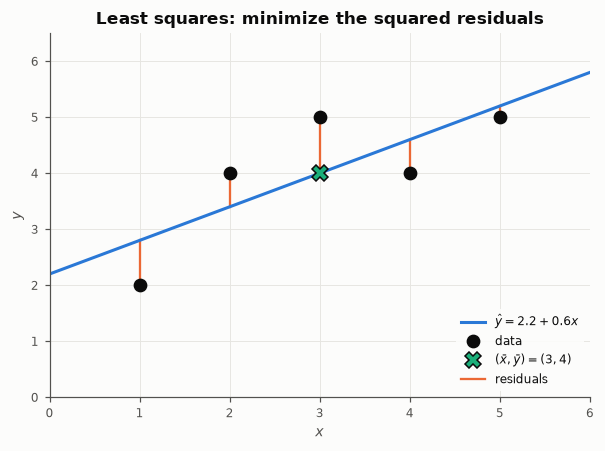

In [6]:
x = np.array([1, 2, 3, 4, 5.]); y = np.array([2, 4, 5, 4, 5.])
b1, b0 = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]
print(f"b0 = {b0:.2f}, b1 = {b1:.2f}, r = {r:.3f}")

fig, ax = plt.subplots(figsize=(5.6, 4.2))
data_axes(ax, "Least squares: minimize the squared residuals", "$x$", "$y$")
xx = np.linspace(0, 6, 50); yhat = b0 + b1*x
for xi, yi, yh in zip(x, y, yhat):
    ax.plot([xi, xi], [yi, yh], color=ORANGE, lw=1.5)
ax.plot(xx, b0 + b1*xx, color=BLUE, label=r"$\hat{y} = 2.2 + 0.6x$")
ax.plot(x, y, "o", ms=8, color=INK, label="data", zorder=5)
ax.plot([3], [4], marker="X", ms=11, color=AQUA, mec=INK, ls="none", label=r"$(\bar{x}, \bar{y}) = (3, 4)$", zorder=6)
ax.plot([], [], color=ORANGE, lw=1.5, label="residuals")
ax.set_xlim(0, 6); ax.set_ylim(0, 6.5); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### The correlation coefficient $r$

$$
r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}, \qquad -1 \le r \le 1
$$

For the worked example, $\sum (y_i - \bar{y})^2 = 4 + 0 + 1 + 0 + 1 = 6$, so $r = \dfrac{6}{\sqrt{10 \cdot 6}} \approx 0.775$.

| Value of $r$ | Meaning |
|---|---|
| near $1$ | points close to an increasing line |
| near $-1$ | points close to a decreasing line |
| near $0$ | no **linear** pattern (there may still be a strong curved one) |

- $r$ measures how tightly points cluster around a line, **not** how steep the line is.
- $r$ and the slope $b_1$ always have the same sign.
- Only interpret $r$ (and the fitted line) when the scatter plot looks linear.

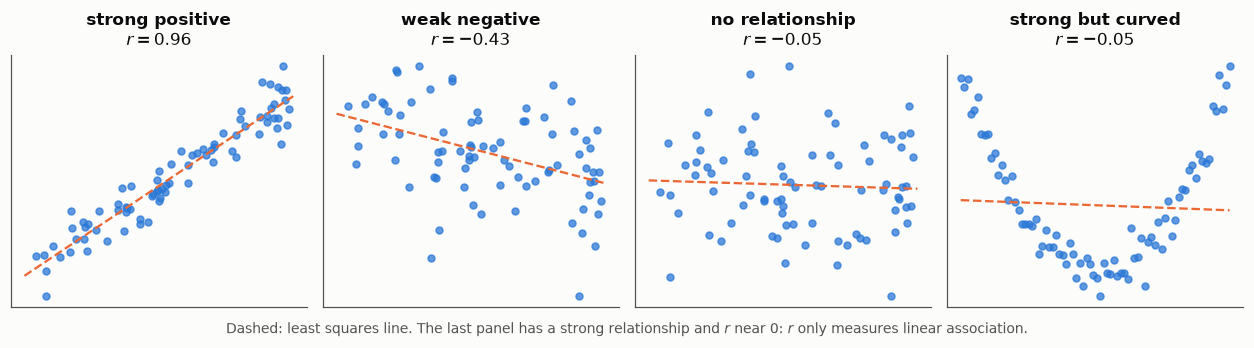

In [7]:
rng = np.random.default_rng(4)
n = 80
x = rng.uniform(-2, 2, n)
cases = [
    ("strong positive", 1.5*x + rng.normal(0, 0.5, n)),
    ("weak negative", -0.5*x + rng.normal(0, 1.2, n)),
    ("no relationship", rng.normal(0, 1, n)),
    ("strong but curved", None),
]
xs = np.linspace(-2, 2, n)
fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.0), sharex=True)
for ax, (label, y) in zip(axes, cases):
    if y is None:
        x = xs; y = x**2 + rng.normal(0, 0.25, n)
    r = np.corrcoef(x, y)[0, 1]
    data_axes(ax, f"{label}\n$r = {r:.2f}$")
    ax.plot(x, y, "o", ms=4.5, color=BLUE, alpha=0.75)
    b1, b0 = np.polyfit(x, y, 1); xx = np.array([-2, 2])
    ax.plot(xx, b0 + b1*xx, color=ORANGE, lw=1.5, ls="--")
    ax.set_xticks([]); ax.set_yticks([])
fig.text(0.5, -0.03, "Dashed: least squares line. The last panel has a strong relationship and $r$ near 0: "
         "$r$ only measures linear association.", ha="center", color=INK2, fontsize=9)
plt.tight_layout(); plt.show()

### Interpolation versus extrapolation

The simulated example below fits a line to tree heights for small trees only. Inside that range the line works well. Extended to large trees, it badly overpredicts, because height growth levels off.

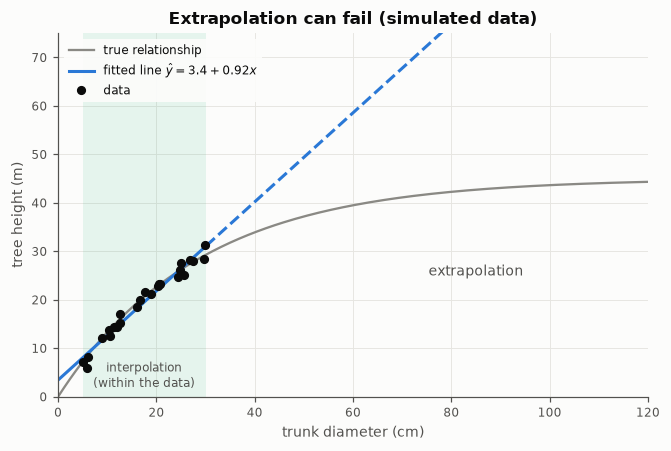

In [8]:
rng = np.random.default_rng(7)
dbh = np.sort(rng.uniform(5, 30, 25))
height = 45*(1 - np.exp(-0.035*dbh)) + rng.normal(0, 1.0, dbh.size)   # simulated, saturating curve
b1, b0 = np.polyfit(dbh, height, 1)

fig, ax = plt.subplots(figsize=(6.2, 4.2))
data_axes(ax, "Extrapolation can fail (simulated data)", "trunk diameter (cm)", "tree height (m)")
ax.axvspan(5, 30, color=AQUA, alpha=0.10, lw=0)
xx = np.linspace(0, 120, 200)
ax.plot(xx, 45*(1 - np.exp(-0.035*xx)), color=GRAY, lw=1.5, label="true relationship")
ax.plot(xx[xx <= 30], b0 + b1*xx[xx <= 30], color=BLUE, label=f"fitted line $\\hat{{y}} = {b0:.1f} + {b1:.2f}x$")
ax.plot(xx[xx >= 30], b0 + b1*xx[xx >= 30], color=BLUE, ls="--")
ax.plot(dbh, height, "o", ms=5, color=INK, label="data", zorder=5)
ax.text(17.5, 2, "interpolation\n(within the data)", ha="center", color=INK2, fontsize=8)
ax.text(85, 25, "extrapolation", ha="center", color=INK2, fontsize=9)
ax.set_xlim(0, 120); ax.set_ylim(0, 75); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Reading $r$ as the slope. A nearly flat line can have $r = 0.99$ if the points hug it tightly.
- Concluding "no relationship" from $r \approx 0$ without looking at the plot. A U-shaped pattern gives $r$ near $0$.
- Reporting a fitted line for clearly curved data.
- Treating extrapolation like interpolation. The fitted line describes the data range, nothing more.
- Inferring causation from correlation. A strong $r$ says the points are close to a line, not why.
:::

:::{important} The book underplays this
The book hands least squares to the calculator and never gives the formulas for $b_1$ and $b_0$ or says that the line passes through $(\bar{x}, \bar{y})$. Learn the formulas above; they come back as the matrix formula $\hat{\boldsymbol\beta} = (X^\top X)^{-1} X^\top \mathbf{y}$ in Searle. The book's line "the closer $r$ is to 0, the more scattered the data" is also misleading, as the curved panel shows. For the Technology exercises, use Python (`np.polyfit(x, y, 1)` and `np.corrcoef(x, y)`) instead of a graphing calculator.
:::

:::{tip} Where this shows up
This is simple linear regression, the base case of nearly every model you'll fit: GLMs, mixed models, occupancy models with covariates, and Bayesian regression in Hoff Ch. 9. Squared residuals connect to the normal likelihood: the least squares line is the maximum likelihood estimate when errors are normal. Extrapolation is the classic trap in species distribution models projected to new climates.
:::

## Exercises to prioritize

Odd numbers have answers in the back.

| Section | Core set | Notes |
|---|---|---|
| 4.1 | Algebraic 7–55 odd; Graphical 57–87 odd; Numeric 89–95 odd | Long section. 29–36 (equations from given information) and 47–55 (parallel/perpendicular) are the most important. Extensions 105–113 odd if you're moving fast. |
| 4.2 | Algebraic 5–29 odd; Graphical 31–37 odd; Numeric 39–43 odd; Real-World 45–57 odd | Real-World is the point of this section. Add 49 and 50 (moose, owl). |
| 4.3 | Verbal 1–5 (all); Algebraic 6–13; Graphical 14–21; Numeric 22–24; Technology 25–31 odd; Real-World 37–41 odd | Do the Technology problems in Python, and compute one fit by hand with the formulas. |

**Cold diagnostic.** A few days after the section work, do the **Practice Test** (1–33), timed and with no notes. The **Review Exercises** (1–45, grouped by section) are the follow-up for weak spots.